# Nested rings
Enter a value (LEN). The notebook builds the ladder LEN, LEN//2, ..., 1 as solid nested rings. A ring of LEN n is n slices per word, thickness n, touching the ring inside it.
Word order is a hook: `ORDER_OVERRIDE[L] = [...]` replaces the default (counting order) for that ring.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge
import math, random

VALUE = 8                 # <- enter a value here (or use the box in the last cell)
ORDER_OVERRIDE = {}       # e.g. {3: ["000","010","110","011","101","111"]}  (any ring, explicit word order)
DRAW_MAX = 8              # largest ring that gets drawn (ring 8 = 2048 slices)
BUILD_MAX = 12            # largest ring built as explicit data

In [2]:
def chain(v):
    out = []
    while v >= 1: out.append(v); v //= 2
    return out[::-1]                      # smallest (core) first

def partner(x):                          # the word across the fold: mirror image; a palindrome takes its complement
    r = x[::-1]
    return r if r != x else "".join("1" if ch == "0" else "0" for ch in x)

def grow(L):
    """Grow outward-in. Ends first (all 0 / all 1), then each next pair is inserted at the exact center of what exists.
    Pairs are taken in ascending order of their smaller word. The last pair (the center) sits swapped."""
    seen, pairs = set(), []
    for w in range(1 << L):
        x = format(w, f"0{L}b")
        if x in seen: continue
        p = partner(x); seen |= {x, p}; pairs.append((x, p))
    seq = []
    for i, (a, b) in enumerate(pairs):
        if i == len(pairs) - 1 and len(pairs) > 1: a, b = b, a
        mid = len(seq) // 2
        seq = seq[:mid] + [a, b] + seq[mid:]
    return seq

def words(L):
    if L in ORDER_OVERRIDE: return list(ORDER_OVERRIDE[L])
    return grow(L)

def ring_string(L): return "".join(words(L))               # every slice, clockwise

def build(v):
    return {L: ring_string(L) for L in chain(v) if L <= BUILD_MAX}


In [3]:
TEAL, GRAY = "#5DCAA5", "#EDEDED"

def draw(v):
    rings = build(v); ls = [L for L in chain(v) if L in rings and L <= DRAW_MAX]
    fig, ax = plt.subplots(figsize=(8, 8)); r0 = 0
    for L in chain(v):
        r1 = r0 + L
        if L in ls:
            s = rings[L]; n = len(s); span = 360 / n
            for i, ch in enumerate(s):
                a0, a1 = i * span, (i + 1) * span
                ax.add_patch(Wedge((0, 0), r1, 90 - a1, 90 - a0, width=L, facecolor=TEAL if ch == "1" else GRAY,
                                   edgecolor=(TEAL if ch == "1" else GRAY) if n > 128 else "#555", linewidth=0.3 if n > 128 else 0.6))
                if n <= 64:
                    m = math.radians(90 - (a0 + a1) / 2); rm = (r0 + r1) / 2
                    ax.text(rm * math.cos(m), rm * math.sin(m), ch, ha="center", va="center", fontsize=8)
            w = words(L); gs = 360 / len(w)
            for j in range(len(w)):
                ax.add_patch(Wedge((0, 0), r1, 90 - (j + 1) * gs, 90 - j * gs, width=L, fill=False,
                                   edgecolor="#222", linewidth=1.6 if len(w) <= 64 else 0.8))
        r0 = r1
    R = sum(chain(v)); ax.set_xlim(-R - 1, R + 1); ax.set_ylim(-R - 1, R + 1); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"Rings {chain(v)} (drawn: {ls}); teal = 1, gray = 0; slices run clockwise from the top")
    return fig

In [4]:
# route: same angle, next ring in. The entry never chooses it. Works for any ring size (exact integers).
def size(L): return L * (1 << L)
def bit(L, o):
    w, k = divmod(o % size(L), L); return (w >> (L - 1 - k)) & 1
def window(L, o):
    v = 0
    for i in range(L): v = (v << 1) | bit(L, o + i)
    return v
def fall(L, o): return (o * size(L // 2)) // size(L)
def trace(L, o):
    path = []
    while True:
        path.append((L, o, window(L, o)))
        if L == 1: return path
        o, L = fall(L, o), L // 2
def show_trace(v, entry=None):
    o = entry if entry is not None else random.randrange(size(v))
    print("entry slice", o)
    for L, off, w in trace(v, o): print(f"  ring {L:3d}  offset {off}  reads {w:0{L}b}")

In [5]:
# LEN 3 should read 000 001 010 110 011 101 100 111; no word twice at any length.
print("LEN 2:", " ".join(words(2)))
print("LEN 3:", " ".join(words(3)))
print("LEN 4:", " ".join(words(4)))
assert words(3) == "000 001 010 110 011 101 100 111".split()
assert all(len(set(words(L))) == 1 << L for L in range(1, 11))
print("every word once, LEN 1-10")


LEN 2: 00 10 01 11
LEN 3: 000 001 010 110 011 101 100 111
LEN 4: 0000 0001 0010 0011 0101 0110 0111 1101 1011 1110 1001 1010 1100 0100 1000 1111
every word once, LEN 1-10


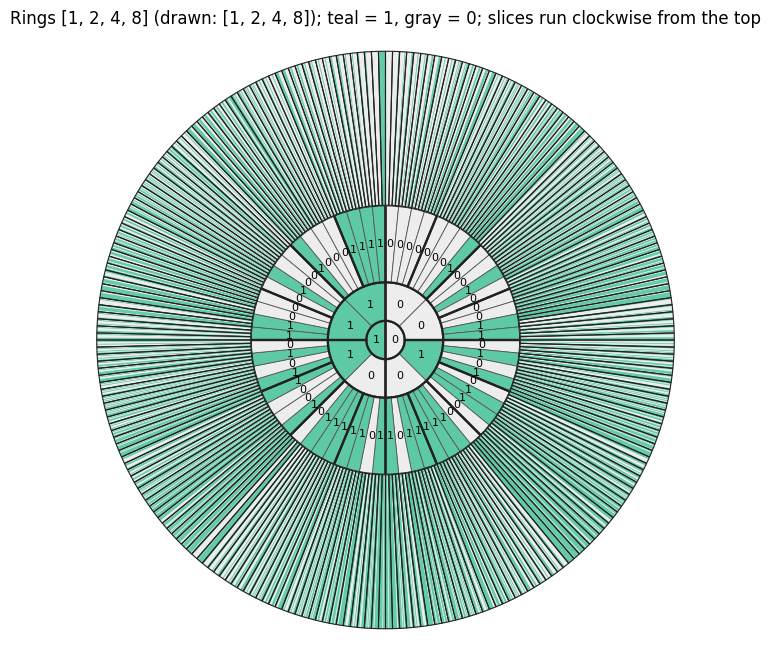

entry slice 1299
  ring   8  offset 1299  reads 00010101
  ring   4  offset 40  reads 1010
  ring   2  offset 5  reads 01
  ring   1  offset 1  reads 1


In [12]:
fig = draw(VALUE); plt.show()
show_trace(VALUE)

In [13]:
# Optional: a box to enter the value (needs ipywidgets). Otherwise just change VALUE above and re-run.
try:
    import ipywidgets as W
    from IPython.display import clear_output, display
    box = W.BoundedIntText(value=VALUE, min=1, max=64, description="LEN:")
    out = W.Output()
    def go(change=None):
        with out:
            clear_output(wait=True); draw(box.value); plt.show(); show_trace(box.value)
    box.observe(go, names="value"); display(box, out); go()
except ImportError:
    print("ipywidgets not installed: edit VALUE and re-run the cell above.")

BoundedIntText(value=8, description='LEN:', max=64, min=1)

Output()